# ML-Driven Probabilistic Forecasting — 2027 AFC Asian Cup
**Step 1: model testing (Elo → features → 3 models → evaluation).** Omar Elouny · CSCI-630.01

Follows the proposal: Elo ratings (1872–2026) with tournament weighting, goal-margin multipliers and successor mappings; engineered features (Elo differences, rolling form, rest days, host advantage); chronological splits; three models (Poisson GLM / Logistic Regression baseline, XGBoost, MLP); evaluation by multi-class log loss, Brier score and calibration curves; selection of the best-calibrated model as the match simulation engine (Monte Carlo comes in the next step).

**Split (chronological):** Train ≤ 2019 · Validation 2020–2022 · Test 2023+ · **Scope:** full history (1872+).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import defaultdict, deque
from scipy.stats import poisson
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss, accuracy_score
import xgboost as xgb
DATA = "/tmp/claude-0/ds/"
SEED = 42; np.random.seed(SEED)
plt.rcParams.update({"figure.dpi":110, "axes.grid":True, "grid.alpha":.3})

## 1. Load data & map former team names to current names (successor mappings)

In [2]:
res = pd.read_csv(DATA+"results.csv", parse_dates=["date"])
fn  = pd.read_csv(DATA+"former_names.csv", parse_dates=["start_date","end_date"])
res = res.dropna(subset=["home_score","away_score"]).sort_values("date", kind="stable").reset_index(drop=True)
res["neutral"] = res["neutral"].astype(str).str.upper().eq("TRUE")
orig_names = res[["home_team","away_team"]].copy()
for _, r in fn.iterrows():
    m = (res.date >= r.start_date) & (res.date <= r.end_date)
    for c in ["home_team","away_team"]:
        res.loc[m & (res[c]==r.former), c] = r.current
print(f"{len(res):,} matches, {res.date.min().date()} → {res.date.max().date()}")
print("name cells remapped:", int((orig_names.values != res[["home_team","away_team"]].values).sum()))
res.tail(3)

49,945 matches, 1872-11-30 → 2026-10-06
name cells remapped: 0


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
49942,2026-10-06,Antigua and Barbuda,Aruba,3,2,CONCACAF Nations League,North Sound,Antigua and Barbuda,False
49943,2026-10-06,Saint Martin,Bahamas,6,0,CONCACAF Nations League,St Croix,United States Virgin Islands,True
49944,2026-10-06,Saudi Arabia,United Arab Emirates,2,0,Gulf Cup,Jeddah,Saudi Arabia,False


## 2. Elo ratings + match-level features (all computed *before* each match → no leakage)

* Start rating 1500; home advantage +100 Elo when the match is not neutral.
* **Tournament weighting** (K): World Cup 60 · continental finals 50 · WC/continental qualifiers & Nations League 40 · other competitive 30 · friendly 20.
* **Goal-margin multiplier** (World Football Elo): 1 for margin ≤1, 1.5 for 2, (11+margin)/8 for ≥3.
* Rolling form (last 5 points-per-game, last 10 goals for/against), rest days, host advantage, experience.

In [3]:
def k_weight(t):
    t = t.lower()
    if t == "fifa world cup": return 60
    if "qualification" in t or "nations league" in t: return 40
    if t == "friendly": return 20
    if any(s in t for s in ["uefa euro","copa américa","african cup of nations","afc asian cup","gold cup","confederations cup","oceania nations cup","concacaf championship","conmebol"]): return 50
    return 30
def gm_mult(d):
    d = abs(d); return 1.0 if d<=1 else (1.5 if d==2 else (11+d)/8)

res["K"] = res.tournament.map(k_weight)
elo = defaultdict(lambda: 1500.0); last_date = {}; n_played = defaultdict(int)
pts = defaultdict(lambda: deque(maxlen=5)); gf = defaultdict(lambda: deque(maxlen=10)); ga = defaultdict(lambda: deque(maxlen=10))
HOME_ADV = 100; rows = []
def form(team):
    p = np.mean(pts[team]) if pts[team] else 1.0
    f = np.mean(gf[team]) if gf[team] else 1.3
    a = np.mean(ga[team]) if ga[team] else 1.3
    return p, f, a
for r in res.itertuples(index=False):
    h, a = r.home_team, r.away_team
    eh, ea = elo[h], elo[a]
    ph, fh, ah = form(h); pa, fa, aa = form(a)
    rest_h = min((r.date-last_date[h]).days, 60) if h in last_date else 60
    rest_a = min((r.date-last_date[a]).days, 60) if a in last_date else 60
    host = 1 if (not r.neutral) or r.country==h else (-1 if r.country==a else 0)
    rows.append((eh, ea, ph, pa, fh, fa, ah, aa, rest_h, rest_a, host, np.log1p(n_played[h]), np.log1p(n_played[a])))
    # update
    adv = 0 if r.neutral else HOME_ADV
    exp_h = 1/(1+10**(-((eh+adv)-ea)/400))
    S = 1.0 if r.home_score>r.away_score else (0.5 if r.home_score==r.away_score else 0.0)
    delta = r.K*gm_mult(r.home_score-r.away_score)*(S-exp_h)
    elo[h] += delta; elo[a] -= delta
    for t, gfor, gag in [(h, r.home_score, r.away_score), (a, r.away_score, r.home_score)]:
        pts[t].append(3 if gfor>gag else (1 if gfor==gag else 0)); gf[t].append(gfor); ga[t].append(gag)
        last_date[t] = r.date; n_played[t] += 1
cols = ["elo_home","elo_away","form_pts_home","form_pts_away","gf10_home","gf10_away","ga10_home","ga10_away","rest_home","rest_away","host_adv","exp_home","exp_away"]
F = pd.DataFrame(rows, columns=cols)
df = pd.concat([res, F], axis=1)
df["elo_diff"]  = df.elo_home - df.elo_away
df["form_diff"] = df.form_pts_home - df.form_pts_away
df["atk_def_home"] = df.gf10_home - df.ga10_away      # home attack vs away defence
df["atk_def_away"] = df.gf10_away - df.ga10_home
df["rest_diff"] = df.rest_home - df.rest_away
df["neutral_i"] = df.neutral.astype(int)
df["is_friendly"] = (df.tournament=="Friendly").astype(int)
df["y"] = np.where(df.home_score>df.away_score, 0, np.where(df.home_score==df.away_score, 1, 2))   # 0=Home win 1=Draw 2=Away win
FEATS = ["elo_diff","elo_home","elo_away","form_diff","form_pts_home","form_pts_away","atk_def_home","atk_def_away",
         "rest_diff","host_adv","neutral_i","K","is_friendly","exp_home","exp_away"]
cur = pd.Series(dict(elo)).sort_values(ascending=False)
print("Top-10 current Elo:\n", cur.head(10).round(0).to_string())
print("\nSaudi Arabia:", round(elo["Saudi Arabia"]), "| Japan:", round(elo["Japan"]), "| Iran:", round(elo["Iran"]), "| South Korea:", round(elo["South Korea"]))

Top-10 current Elo:
 Spain          2357.0
Argentina      2255.0
England        2220.0
France         2176.0
Portugal       2121.0
Brazil         2089.0
Colombia       2075.0
Switzerland    2050.0
Netherlands    2048.0
Belgium        2034.0

Saudi Arabia: 1739 | Japan: 1975 | Iran: 1865 | South Korea: 1845


## 3. Chronological split (Train ≤2019 · Val 2020–2022 · Test 2023+)

In [4]:
tr = df[df.date.dt.year<=2019]; va = df[df.date.dt.year.between(2020,2022)]; te = df[df.date.dt.year>=2023]
print({k: len(v) for k,v in dict(train=tr, val=va, test=te).items()})
print("Class balance (H/D/A):"); print(pd.DataFrame({n: d.y.value_counts(normalize=True).sort_index().round(3) for n,d in dict(train=tr,val=va,test=te).items()}).set_axis(["Home","Draw","Away"]))
Xtr, Xva, Xte = tr[FEATS].values, va[FEATS].values, te[FEATS].values
ytr, yva, yte = tr.y.values, va.y.values, te.y.values

{'train': 43406, 'val': 2441, 'test': 4098}
Class balance (H/D/A):
      train    val   test
Home  0.492  0.483  0.472
Draw  0.227  0.232  0.228
Away  0.281  0.285  0.300


## 4. Evaluation helpers — multi-class log loss, Brier score, RPS, accuracy, calibration (ECE)

In [5]:
def brier(P, y):  return np.mean(np.sum((P - np.eye(3)[y])**2, axis=1))
def rps(P, y):
    cp, co = np.cumsum(P,1)[:,:2], np.cumsum(np.eye(3)[y],1)[:,:2]
    return np.mean(np.sum((cp-co)**2,1)/2)
def ece(P, y, bins=10):
    out=[]
    for k in range(3):
        b = pd.qcut(P[:,k], bins, duplicates="drop"); g = pd.DataFrame({"p":P[:,k],"o":(y==k).astype(float),"b":b}).groupby("b", observed=True)
        s = g.agg(p=("p","mean"), o=("o","mean"), n=("p","size")); out.append((s.n*(s.p-s.o).abs()).sum()/s.n.sum())
    return float(np.mean(out))
def evaluate(P, y):
    P = np.clip(P,1e-12,1); P = P/P.sum(1,keepdims=True)
    ll_i = -np.log(P[np.arange(len(y)), y])
    return dict(LogLoss=ll_i.mean(), LL_SE=ll_i.std()/np.sqrt(len(y)), Brier=brier(P,y), RPS=rps(P,y), Accuracy=accuracy_score(y,P.argmax(1)), ECE=ece(P,y))
def poisson_to_wdl(lh, la, maxg=12):
    g = np.arange(maxg+1); ph = poisson.pmf(g[None,:], lh[:,None]); pa = poisson.pmf(g[None,:], la[:,None])
    M = ph[:,:,None]*pa[:,None,:]
    pH = np.array([np.tril(m,-1).sum() for m in M])
    pD = np.array([np.trace(m) for m in M]); pA = np.array([np.triu(m,1).sum() for m in M])
    P = np.c_[pH,pD,pA]; return P/P.sum(1,keepdims=True)
prior = np.bincount(ytr, minlength=3)/len(ytr)
preds = {"_Class-prior reference": {"val": np.tile(prior,(len(yva),1)), "test": np.tile(prior,(len(yte),1))}}

## 5. Model A — baseline: Poisson GLM (goals → W/D/L) and multinomial Logistic Regression
The Poisson GLM predicts expected goals for each side; independent Poisson score grids give W/D/L probabilities (and goal predictions for the later simulation).

In [6]:
# Poisson GLM: two regressions (home goals, away goals); regularisation chosen on validation log loss
def glm_design(d):
    return np.c_[d.elo_diff/100, d.elo_home/100, d.elo_away/100, d.form_pts_home, d.form_pts_away, d.atk_def_home, d.atk_def_away,
                 d.host_adv, d.neutral_i, d.is_friendly, d.rest_diff/30]
best=None
for alpha in [0, 1e-4, 1e-3, 1e-2, 0.1, 1.0]:
    mh = make_pipeline(StandardScaler(), PoissonRegressor(alpha=alpha, max_iter=1000)).fit(glm_design(tr), tr.home_score)
    ma = make_pipeline(StandardScaler(), PoissonRegressor(alpha=alpha, max_iter=1000)).fit(glm_design(tr), tr.away_score)
    P = poisson_to_wdl(mh.predict(glm_design(va)), ma.predict(glm_design(va)))
    ll = log_loss(yva, P, labels=[0,1,2])
    if best is None or ll<best[0]: best=(ll,alpha,mh,ma)
print("Poisson GLM best alpha:", best[1], "val log loss", round(best[0],4))
glm_h, glm_a = best[2], best[3]
lh_va, la_va = glm_h.predict(glm_design(va)), glm_a.predict(glm_design(va))
lh_te, la_te = glm_h.predict(glm_design(te)), glm_a.predict(glm_design(te))
preds["Poisson GLM"] = {"val": poisson_to_wdl(lh_va,la_va), "test": poisson_to_wdl(lh_te,la_te)}

# Goal-prediction quality on the test set
gl = pd.DataFrame({"": ["Home goals","Away goals"],
    "Mean actual": [te.home_score.mean(), te.away_score.mean()], "Mean predicted": [lh_te.mean(), la_te.mean()],
    "MAE": [np.abs(te.home_score-lh_te).mean(), np.abs(te.away_score-la_te).mean()],
    "RMSE": [np.sqrt(((te.home_score-lh_te)**2).mean()), np.sqrt(((te.away_score-la_te)**2).mean())]}).set_index("")
display(gl.round(3))

# Logistic regression
bestlr=None
for C in [0.001,0.01,0.1,1,10]:
    m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000)).fit(Xtr, ytr)
    ll = log_loss(yva, m.predict_proba(Xva), labels=[0,1,2])
    if bestlr is None or ll<bestlr[0]: bestlr=(ll,C,m)
print("Logistic Regression best C:", bestlr[1], "val log loss", round(bestlr[0],4))
preds["Logistic Regression"] = {"val": bestlr[2].predict_proba(Xva), "test": bestlr[2].predict_proba(Xte)}

Poisson GLM best alpha: 0 val log loss 0.8792


,Mean actual,Mean predicted,MAE,RMSE
,,,,
Home goals,1.629,1.892,1.104,1.425
Away goals,1.159,1.201,0.877,1.165


Logistic Regression best C: 10 val log loss 0.8726


## 6. Model B — XGBoost classifier (hyper-parameters + early stopping on the validation set)

XGBoost best: depth=2 min_child_weight=20 trees=487 val log loss=0.8713


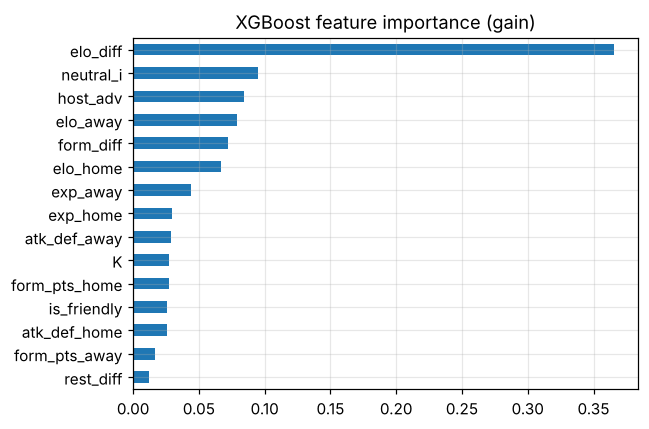

In [7]:
bestx=None
for depth in [2,3,4,6]:
    for mcw in [5,20]:
        m = xgb.XGBClassifier(objective="multi:softprob", n_estimators=1500, learning_rate=0.03, max_depth=depth, min_child_weight=mcw,
                              subsample=0.8, colsample_bytree=0.8, reg_lambda=5, eval_metric="mlogloss",
                              early_stopping_rounds=60, n_jobs=2, random_state=SEED)
        m.fit(Xtr, ytr, eval_set=[(Xva,yva)], verbose=False)
        ll = m.best_score
        if bestx is None or ll<bestx[0]: bestx=(ll,depth,mcw,m.best_iteration,m)
print(f"XGBoost best: depth={bestx[1]} min_child_weight={bestx[2]} trees={bestx[3]+1} val log loss={bestx[0]:.4f}")
xg = bestx[4]
preds["XGBoost"] = {"val": xg.predict_proba(Xva), "test": xg.predict_proba(Xte)}
imp = pd.Series(xg.feature_importances_, index=FEATS).sort_values()
imp.plot.barh(figsize=(6,4), title="XGBoost feature importance (gain)"); plt.tight_layout(); plt.show()

## 7. Model C — Multi-Layer Perceptron (architecture / L2 chosen on validation)

In [8]:
bestm=None
for hl in [(32,),(64,32),(32,16)]:
    for alpha in [1e-3,1e-2,1e-1,1.0]:
        m = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=hl, alpha=alpha, learning_rate_init=1e-3, max_iter=300,
                          early_stopping=True, n_iter_no_change=15, random_state=SEED)).fit(Xtr, ytr)
        ll = log_loss(yva, m.predict_proba(Xva), labels=[0,1,2])
        if bestm is None or ll<bestm[0]: bestm=(ll,hl,alpha,m)
print(f"MLP best: layers={bestm[1]} alpha={bestm[2]} val log loss={bestm[0]:.4f}")
preds["MLP"] = {"val": bestm[3].predict_proba(Xva), "test": bestm[3].predict_proba(Xte)}

MLP best: layers=(64, 32) alpha=1.0 val log loss=0.8729


## 8. Results — validation and test (2023+)
Lower is better for Log Loss / Brier / RPS / ECE. The class-prior row is a no-skill reference, not a candidate model.

In [9]:
def table(split, y):
    t = pd.DataFrame({n: evaluate(p[split], y) for n,p in preds.items()}).T
    return t[["LogLoss","LL_SE","Brier","RPS","Accuracy","ECE"]]
res_val, res_test = table("val", yva), table("test", yte)
print("VALIDATION (2020–2022)"); display(res_val.round(4))
print("TEST (2023+)"); display(res_test.round(4))

VALIDATION (2020–2022)


,LogLoss,LL_SE,Brier,RPS,Accuracy,ECE
_Class-prior reference,1.0481,0.0068,0.6316,0.2267,0.4834,NaN
Poisson GLM,0.8792,0.0128,0.5156,0.1708,0.6010,0.0282
Logistic Regression,0.8726,0.0117,0.5126,0.1696,0.6010,0.0230
XGBoost,0.8713,0.0119,0.5112,0.1690,0.6039,0.0203
MLP,0.8729,0.0112,0.5126,0.1696,0.6055,0.0253


TEST (2023+)


,LogLoss,LL_SE,Brier,RPS,Accuracy,ECE
_Class-prior reference,1.0535,0.0052,0.6359,0.2300,0.4722,NaN
Poisson GLM,0.8803,0.0103,0.5169,0.1727,0.6015,0.0329
Logistic Regression,0.8666,0.0093,0.5093,0.1698,0.6035,0.0255
XGBoost,0.8664,0.0095,0.5093,0.1696,0.6064,0.0206
MLP,0.8665,0.0090,0.5083,0.1693,0.6081,0.0207


In [10]:
# Focus: matches involving an AFC team (inferred from AFC Asian Cup + AFC qualification participants)
afc_t = df[df.tournament.isin(["AFC Asian Cup","AFC Asian Cup qualification"])]
AFC = set(afc_t.home_team)|set(afc_t.away_team)
m_afc = (te.home_team.isin(AFC)|te.away_team.isin(AFC)).values
m_ac  = (te.tournament=="AFC Asian Cup").values
print(f"Test matches with an AFC team: {m_afc.sum()} | 2023 AFC Asian Cup matches in test: {m_ac.sum()}")
sub = pd.DataFrame({n: evaluate(p["test"][m_afc], yte[m_afc]) for n,p in preds.items()}).T[["LogLoss","Brier","RPS","Accuracy","ECE"]]
print("TEST — AFC-involved matches"); display(sub.round(4))
if m_ac.sum()>20:
    sub2 = pd.DataFrame({n: evaluate(p["test"][m_ac], yte[m_ac]) for n,p in preds.items()}).T[["LogLoss","Brier","RPS","Accuracy"]]
    print("TEST — 2023 AFC Asian Cup only"); display(sub2.round(4))

Test matches with an AFC team: 1063 | 2023 AFC Asian Cup matches in test: 51
TEST — AFC-involved matches


,LogLoss,Brier,RPS,Accuracy,ECE
_Class-prior reference,1.0445,0.6291,0.2266,0.4882,NaN
Poisson GLM,0.8706,0.5092,0.1693,0.6068,0.0331
Logistic Regression,0.8583,0.5028,0.1666,0.6068,0.0340
XGBoost,0.8595,0.5042,0.1672,0.6087,0.0262
MLP,0.8574,0.5016,0.1663,0.6096,0.0297


TEST — 2023 AFC Asian Cup only


,LogLoss,Brier,RPS,Accuracy
_Class-prior reference,1.0645,0.6417,0.2201,0.4706
Poisson GLM,0.8929,0.5305,0.1647,0.5882
Logistic Regression,0.8695,0.5183,0.1615,0.5686
XGBoost,0.8841,0.5260,0.1648,0.5686
MLP,0.8738,0.5170,0.1619,0.5686


## 9. Calibration curves (test set, one-vs-rest per outcome, 10 quantile bins)

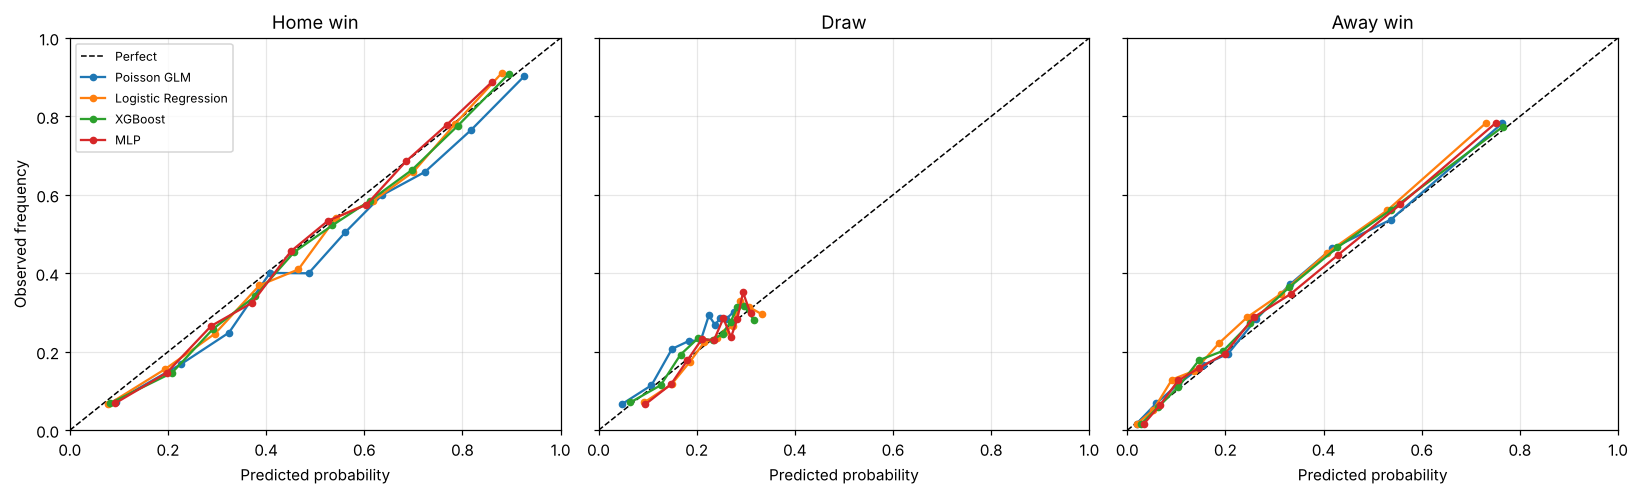

In [11]:
names = [n for n in preds if not n.startswith("_")]; colors = dict(zip(names, ["#1f77b4","#ff7f0e","#2ca02c","#d62728"]))
fig, axes = plt.subplots(1,3, figsize=(15,4.6), sharey=True)
for k, lab in enumerate(["Home win","Draw","Away win"]):
    ax = axes[k]; ax.plot([0,1],[0,1],"k--",lw=1, label="Perfect")
    for n in names:
        p = preds[n]["test"][:,k]; b = pd.qcut(p, 10, duplicates="drop")
        g = pd.DataFrame({"p":p,"o":(yte==k).astype(float),"b":b}).groupby("b",observed=True).mean()
        ax.plot(g.p, g.o, "o-", ms=4, color=colors[n], label=n)
    ax.set_title(lab); ax.set_xlabel("Predicted probability"); ax.set_xlim(0,1); ax.set_ylim(0,1)
axes[0].set_ylabel("Observed frequency"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

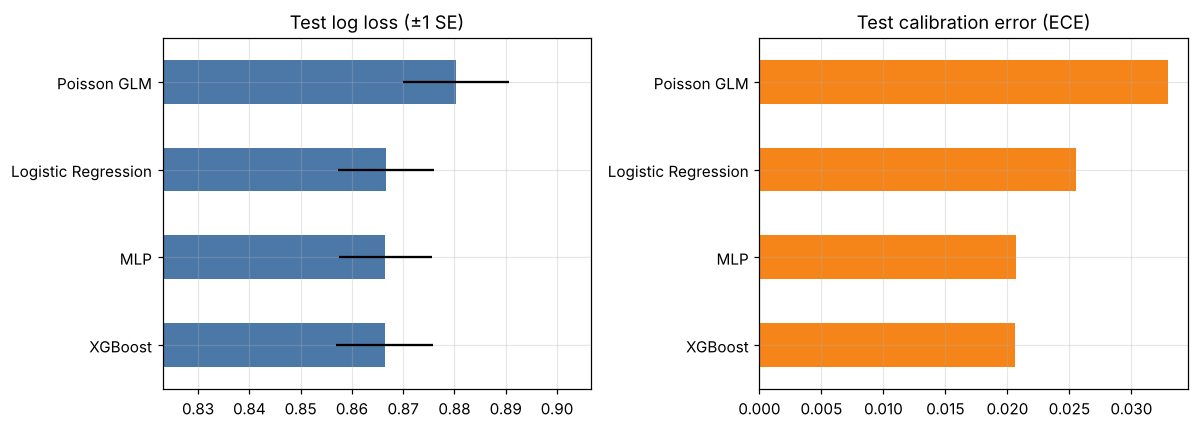

In [12]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
ref = res_test.drop(index=[i for i in res_test.index if i.startswith("_")])
ref["LogLoss"].sort_values().plot.barh(ax=ax[0], xerr=ref["LL_SE"].reindex(ref["LogLoss"].sort_values().index), color="#4c78a8"); ax[0].set_title("Test log loss (±1 SE)"); ax[0].set_xlim(ref.LogLoss.min()*0.95, ref.LogLoss.max()*1.03)
ref["ECE"].sort_values().plot.barh(ax=ax[1], color="#f58518"); ax[1].set_title("Test calibration error (ECE)")
plt.tight_layout(); plt.show()

## 10. Selecting the match-simulation engine
Selection uses the **validation** set only (best log loss and calibration), then confirms on the untouched test set.

In [13]:
cand = res_val.drop(index=[i for i in res_val.index if i.startswith("_")])
rank = pd.DataFrame({"val_LogLoss_rank": cand.LogLoss.rank(), "val_ECE_rank": cand.ECE.rank(), "val_Brier_rank": cand.Brier.rank()})
rank["avg_rank"] = rank.mean(1); rank = rank.sort_values("avg_rank"); display(rank)
best_model = rank.index[0]
print(f"→ Selected simulation engine (validation): {best_model}")
print(f"   Test log loss {res_test.loc[best_model,'LogLoss']:.4f}, Brier {res_test.loc[best_model,'Brier']:.4f}, ECE {res_test.loc[best_model,'ECE']:.4f}")
print(f"   Best on test by log loss: {ref.LogLoss.idxmin()} | by ECE: {ref.ECE.idxmin()}")
pd.concat({"validation":res_val,"test":res_test,"test_AFC_matches":sub}).to_csv("model_results.csv")

,val_LogLoss_rank,val_ECE_rank,val_Brier_rank,avg_rank
XGBoost,1.0,1.0,1.0,1.0
Logistic Regression,2.0,2.0,2.0,2.0
MLP,3.0,3.0,3.0,3.0
Poisson GLM,4.0,4.0,4.0,4.0


→ Selected simulation engine (validation): XGBoost
   Test log loss 0.8664, Brier 0.5093, ECE 0.0206
   Best on test by log loss: XGBoost | by ECE: XGBoost
